# Progress overview: LLM-assisted drift-adaptive federated IDS (CICIoMT2024)

This notebook trains nothing. It reads the results each milestone saved under `reports/` (full pool, seed 42, headline slice `csv_only`) and shows them one milestone at a time. Running it takes seconds. The pipeline itself runs through `scripts/` and the Kaggle notebooks.

Status of every milestone: "Milestone status" in `README_LOCAL.md`, the full project log, which is kept locally and is not in the public repository.

In [1]:
from pathlib import Path
import json, re
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, Image, display

ROOT = Path.cwd() if (Path.cwd() / "reports").exists() else Path.cwd().parent
R = ROOT / "reports"
pd.set_option("display.precision", 4)

def section(path, heading=None):
    """Show one '## heading' section of a report (or the text before the first '##')."""
    text = (R / path).read_text(encoding="utf-8")
    parts = re.split(r"(?m)^## ", text)
    if heading is None:
        body = parts[0]
    else:
        body = next(("## " + p for p in parts[1:] if p.startswith(heading)), None)
        assert body is not None, f"no section {heading!r} in {path}"
    display(Markdown(body))

def fig(path, width=750):
    display(Image(filename=str(R / path), width=width))

def summary(m, method, key="summaries"):
    s = json.loads((R / m / "full/summary.json").read_text())
    return next(x for x in s[key] if x["method"] == method and x["slice"] == "csv_only")

## Status at a glance

In [2]:
log = ROOT / "README_LOCAL.md"  # the full project log, kept locally (not in the public repository)
if log.exists():
    text = log.read_text(encoding="utf-8")
    display(Markdown(text[text.index("## Milestone status"):text.index("## Architecture")]))
else:
    print("README_LOCAL.md not found: the milestone status table is in the local project log only.")

## Milestone status

| #   | Milestone                                          | Proposal mapping              | Status      | Completed |
|-----|----------------------------------------------------|-------------------------------|-------------|-----------|
| M0  | Project scaffolding & environment                  | Reproducibility design        | ✅ Done | 2026-11-04 |
| M1  | Data ingestion, cleaning & label harmonization     | Dataset preparation 1–4       | ✅ Done | 2026-11-04 |
| M2  | Synthetic drift timeline, clients & D_pub          | Time windows, client sim, D_pub | ✅ Done | 2026-11-04 |
| M3  | Edge ensemble + centralized/static baselines       | Edge model, E1, static baseline | ✅ Done (dev + full) | 2026-11-04 |
| M4  | Evaluation harness & metrics                       | Evaluation metrics            | ✅ Done (dev + full) | 2026-11-04 |
| M5  | Drift detection & uncertainty gate                 | ADWIN, PSI/KL/W, gate τc/τd   | ✅ Done (dev + full), acceptance partly met | 2026-11-04 |
| M6  | Incremental local learning + rehearsal buffer      | DA-FedDistill step 1          | ✅ Done (dev + full) | 2026-11-06 |
| M7  | DA-FedDistill (federated distillation)             | E3, novelty claim B           | ✅ Done (dev + full); acceptance met on the full pool's window average only, two seeds | 2026-11-06 |
| M8  | Neural FL baselines (FedAvg / FedProx MLP)         | E2, baselines                 | ✅ Done: dev 3 seeds, full pool 2 seeds at lr 0.03, chosen on full-pool validation rows | 2026-11-07 |
| M9  | Drift-triggered updates, feature selection, adaptive threshold | E4, Methodology Step 5 | ✅ Done (dev + full, two seeds); `e4_added` carried forward (D11) | 2026-11-08 |
| M10 | SHAP explainability (local + global store)         | Novelty claim C               | ✅ Done (dev one seed, full pool two seeds) | 2026-11-08 |
| M11 | Cloud LLM verifier (gated, JSON-constrained)       | E5, E6, novelty claim A       | ✅ Full pool: neither verifier helps. Gemma 2 2B (seeds 42–44) relabels ddos as dos, D3 contains the damage; Mistral 7B (subset) agrees with the edge and fails the JSON contract on 19% | 2026-11-10 |
| M12 | LLM adaptation-policy agent (training decisions)   | "What changes through LLM reasoning" | ✅ Full pool, seeds 42–44: Gemma 2 2B delays every update and loses 0.10 window-average macro-F1 (0.8252 against E4's 0.9241); the heuristic ties E4 | 2026-11-17 |
| M13 | Federated GBDT baseline (stretch)                  | E7                            | ✅ Done: E7 within 0.008 of E1, 0.044 below E3; uplink 760 to 3,200 times E3's | 2026-11-10 |
| M14 | Full experiment matrix, ablations & sensitivity    | E1–E7, ablations, H1–H4       | ✅ Tiers 1–3 done (H1 vs static only; H1 vs naïve, H2, H3 not supported; E3 collapses under strong label skew, α 0.1) | 2026-11-17 |
| M15 | Reproducibility package & paper artifacts          | Notebook A/B, IoT-J outline   | ✅ Done: Notebook A reproduces the headline (largest difference 0.0014) and Notebook B both E4 refits (0.0018), fresh Kaggle clones from the public dataset | 2026-11-18 |

Legend: ⬜ Not started · 🟨 In progress · ✅ Done · ⏸ Blocked

---



## M1: Data ingestion, cleaning and label harmonization

## Raw data
- File: `ciciomt2024_full_8p7m.csv`, 2,404,149,218 bytes, SHA-256 `f7cb6fe30c4e4f0cb415a5e888f9bfcc7a652189a094447c72b8428b6b8f0eb6`
- 8,775,013 rows × 47 columns. NaN: 0, inf: 0
- Constant columns (excluded by the loader): Drate
- Kept as float64 to avoid precision loss: Rate, Srate, AVG, Std, IAT, Magnitue, Radius, Covariance; all others float32
- Processed full parquet: 249 MB

![class counts](class_counts.png)



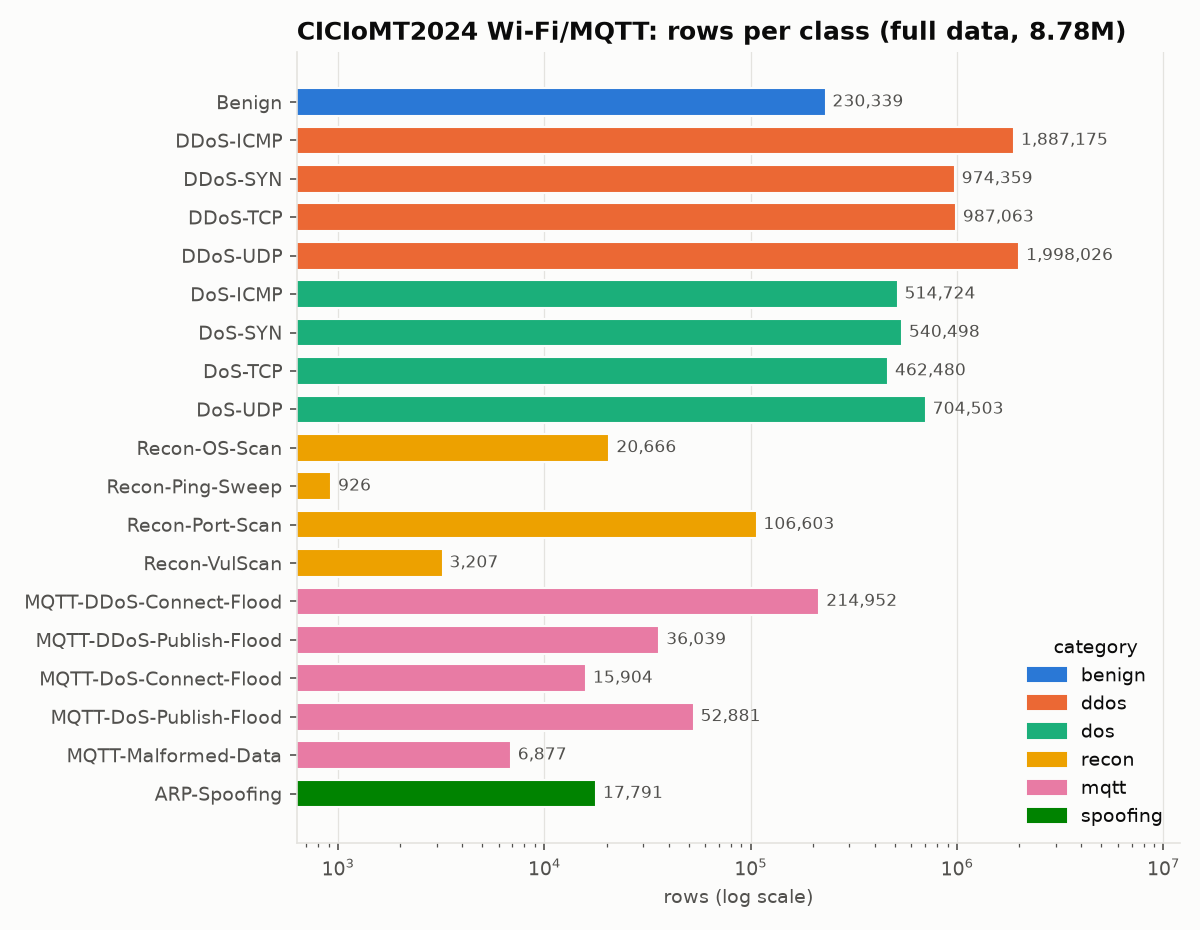

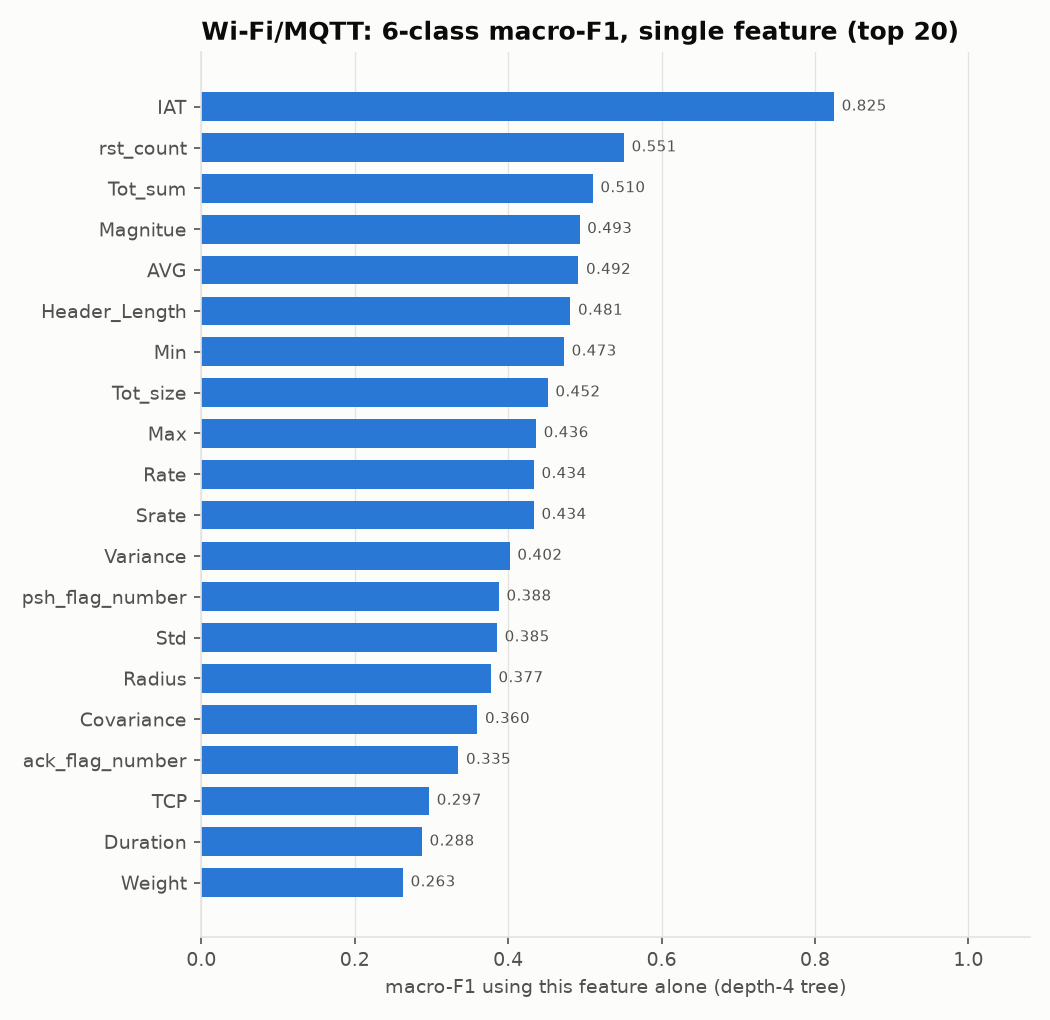

In [3]:
section("m1/EDA.md", "Raw data")
fig("m1/class_counts.png")
fig("m1/single_feature_wifi.png")

## M2: Drift timeline, non-IID clients and D_pub

## Windows

| window | new classes | train rows | test rows | JSD mean | JSD min | JSD max |
|---|---|---:|---:|---:|---:|---:|
| t0 | Benign, DoS-ICMP, DoS-SYN, DoS-TCP, DoS-UDP | 369,950 | 92,485 | 0.167 | 0.066 | 0.332 |
| t1 | DDoS-ICMP, DDoS-SYN, DDoS-TCP, DDoS-UDP | 1,295,948 | 323,984 | 0.195 | 0.078 | 0.318 |
| t2 | Recon-Ping-Sweep, Recon-Port-Scan | 1,316,112 | 329,025 | 0.197 | 0.081 | 0.321 |
| t3 | MQTT-DDoS-Connect-Flood, MQTT-DDoS-Publish-Flood, MQTT-DoS-Connect-Flood, MQTT-DoS-Publish-Flood, MQTT-Malformed-Data | 1,402,345 | 350,585 | 0.203 | 0.080 | 0.320 |
| t4 | ARP-Spoofing | 1,409,385 | 352,346 | 0.204 | 0.082 | 0.321 |
| t5 | Recon-OS-Scan, Recon-VulScan | 1,436,758 | 359,191 | 0.200 | 0.123 | 0.321 |

JSD is the Jensen–Shannon divergence between a client's 19-class training distribution and the whole window's, where 0 = identical and 1 = disjoint. It measures how non-IID the clients are.

![window x class](window_class_counts.png)

![client share](client_class_share.png)

![client jsd](client_jsd.png)



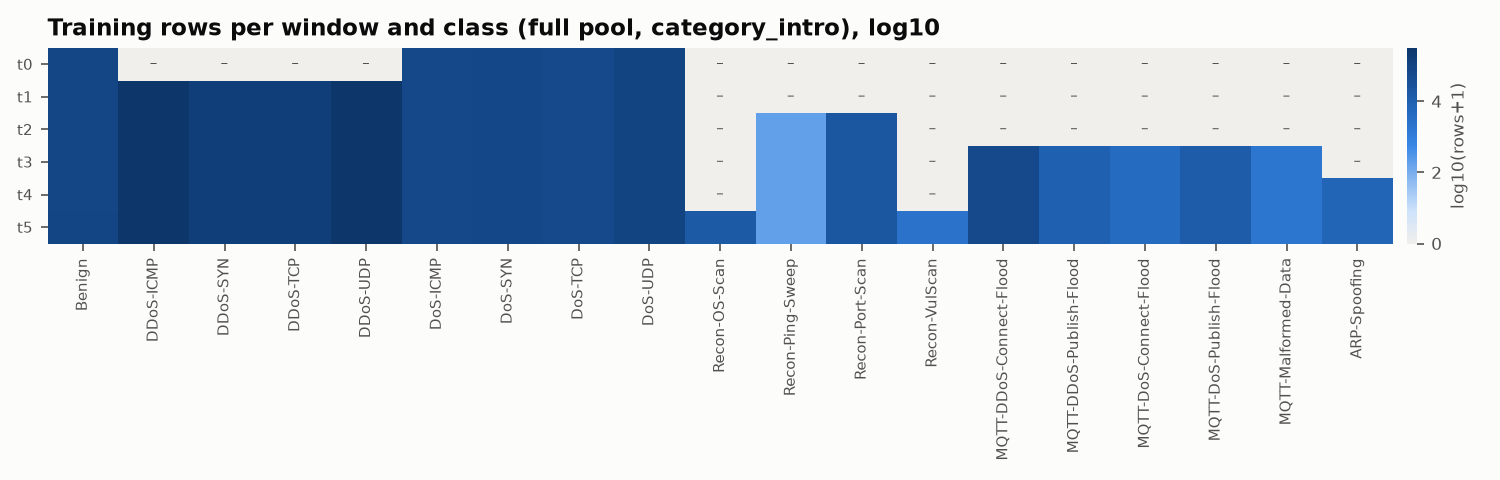

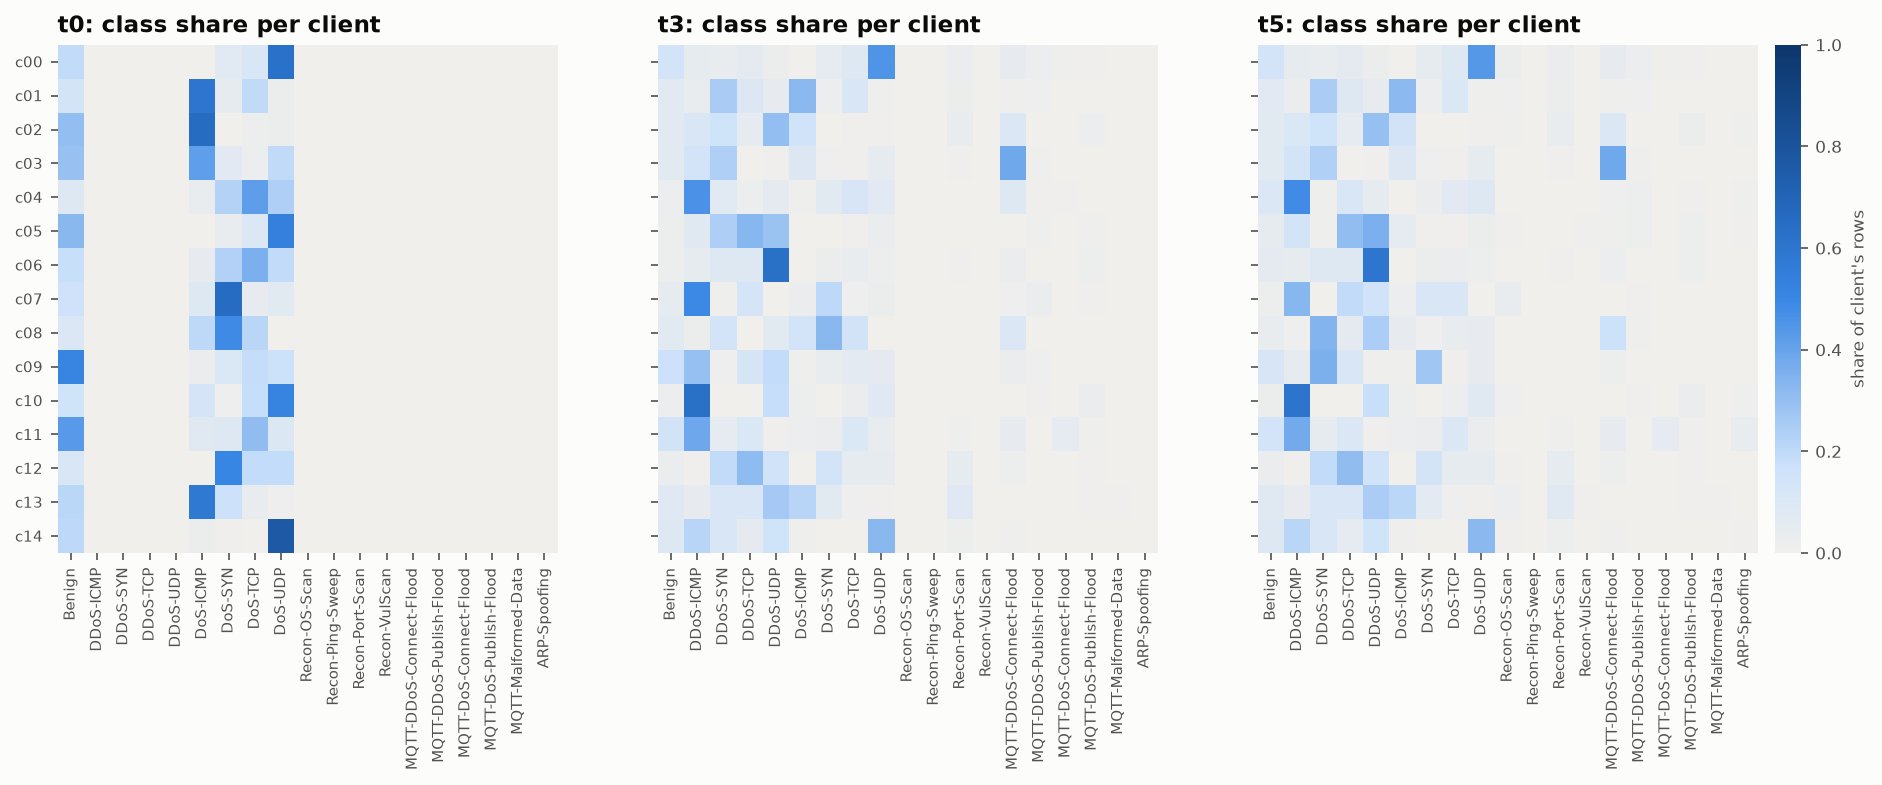

In [4]:
section("m2/full/PARTITION.md", "Windows")
fig("m2/full/window_class_counts.png")
fig("m2/full/client_class_share.png")

## M3: Edge ensemble (XGBoost + LightGBM), centralized E1 vs static

## E1 centralized vs static, on each window's own test set

| window | new classes | E1 centralized macro-F1 | E1 accuracy | static macro-F1 | static accuracy | E1 n_train | w_xgb | T |
|---|---|---:|---:|---:|---:|---:|---:|---:|
| t0 | Benign, DoS-* | 0.9999 | 0.9999 | 0.9999 | 0.9999 | 332,955 | 0.9 | 0.90 |
| t1 | DDoS-* | 0.8311 | 0.8052 | 0.4626 | 0.2854 | 1,499,308 | 0.4 | 0.87 |
| t2 | Recon-Port-Scan, Recon-Ping-Sweep | 0.8683 | 0.8040 | 0.3369 | 0.2811 | 2,683,809 | 0.9 | 0.83 |
| t3 | MQTT-* | 0.8948 | 0.8186 | 0.2631 | 0.2638 | 3,945,919 | 0.3 | 0.83 |
| t4 | ARP-Spoofing | 0.8827 | 0.8147 | 0.2127 | 0.2625 | 5,214,366 | 0.9 | 0.82 |
| t5 | Recon-OS-Scan, Recon-VulScan | 0.8718 | 0.8175 | 0.2089 | 0.2640 | 6,507,448 | 0.1 | 0.83 |

- *E1 centralized* = retrained at every window on all clients' train data for windows 0..t (the upper bound).
- *Static* = trained on t0 only and never updated, which quantifies drift degradation.
- Window-averaged macro-F1: **E1 0.8915**, **static 0.4140**.
- E1 macro-F1 on the cumulative test set (windows 0..t, row-weighted) per t: t0 0.9999, t1 0.8535, t2 0.8586, t3 0.8714, t4 0.8712, t5 0.8713.

![static vs centralized](static_vs_centralized.png)

![matrix](macro_f1_matrix.png)

Each matrix row is one model (trained through window t) and each column is a window's test set. Cells right of the diagonal are future windows the model hasn't seen.



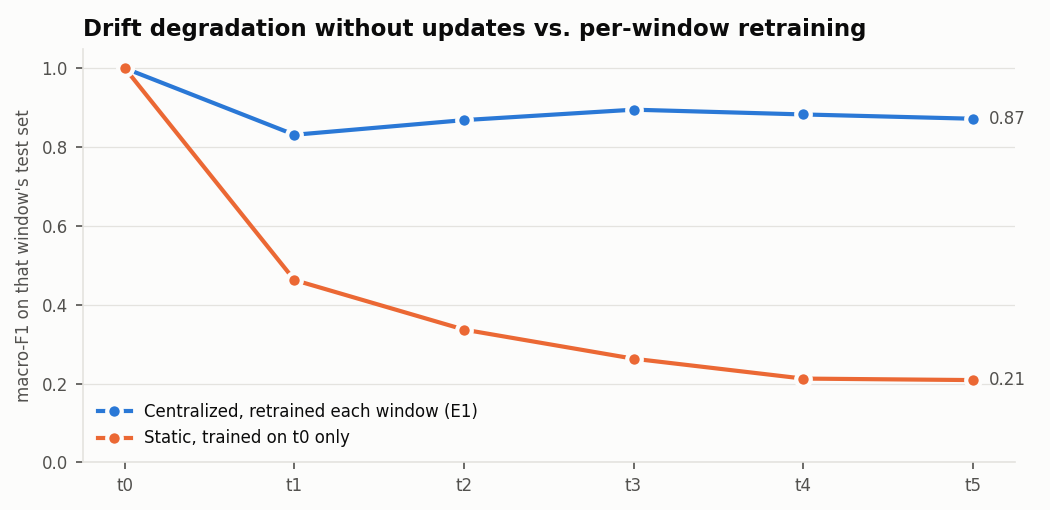

In [5]:
section("m3/full/RESULTS.md", "E1 centralized vs static")
fig("m3/full/static_vs_centralized.png")

## M4: Evaluation harness and metrics

## Summary

| method | slice | window avg | avg excl. t0 | final (t5) | drop from peak | class forgetting | drops | recovered | never |
|---|---|---:|---:|---:|---:|---:|---:|---:|---:|
| E1 | all | 0.8915 | 0.8698 | 0.8718 | 0.1281 | 0.0254 | 4 | 3 | 1 |
| E1 | csv_only | 0.8897 | 0.8677 | 0.8668 | 0.1330 | 0.0277 | 5 | 4 | 1 |
| static | all | 0.4140 | 0.2968 | 0.2089 | 0.7910 | n/a | 4 | 0 | 4 |
| static | csv_only | 0.4024 | 0.2829 | 0.1840 | 0.8159 | n/a | 4 | 0 | 4 |

Class forgetting is F_max − F_final per class on the test set of the window that introduced it, averaged over classes. A static model has one trained state, so it has no forgetting history. A *drop* is a window where the model before its update falls more than ε = 0.02 below its pre-drift score.



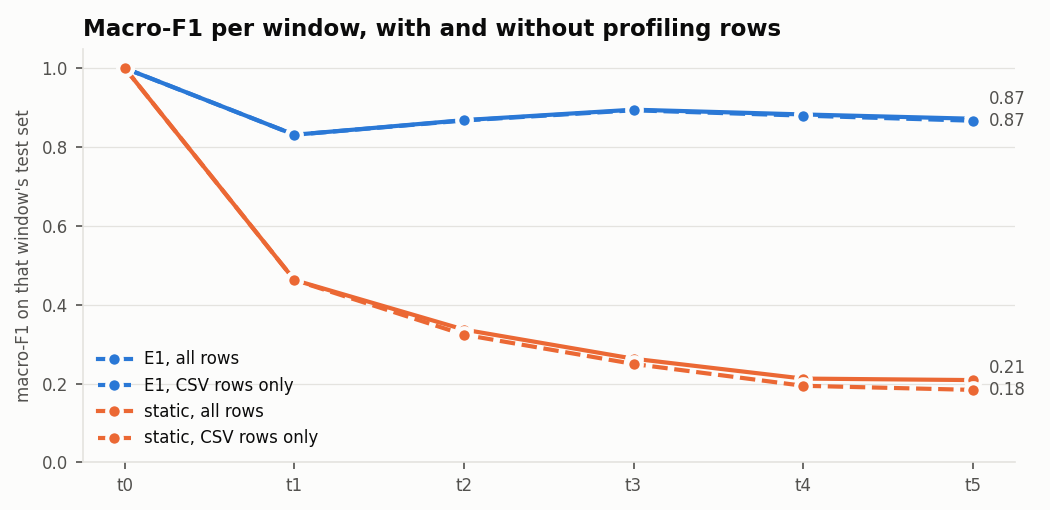

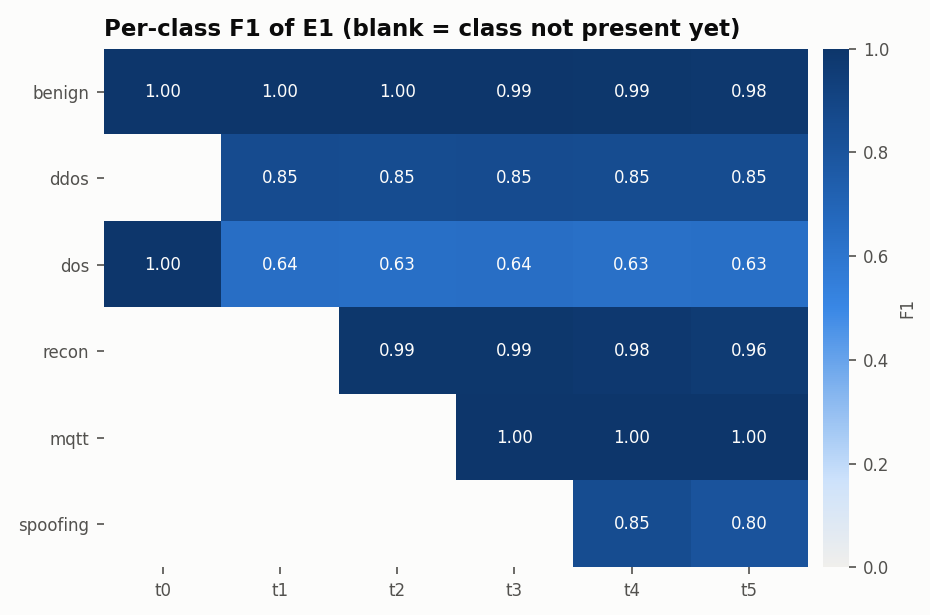

In [6]:
section("m4/full/EVALUATION.md", "Summary")
fig("m4/full/macro_f1_by_window.png")
fig("m4/full/per_class_f1.png")

## M5: Drift detection (ADWIN, PSI) and the uncertainty gate

## ADWIN summary

| signal | clients detected | affected clients detected | boundaries caught, pooled | client false alarms | per 100k rows | pooled false alarms |
|---|---:|---:|---:|---:|---:|---:|
| error | 36/75 | 33/33 | 3/5 | 0 | 0.0 | 0 |
| entropy | 14/75 | 11/33 | 1/5 | 0 | 0.0 | 0 |
| disagreement | 21/75 | 16/33 | 2/5 | 0 | 0.0 | 0 |



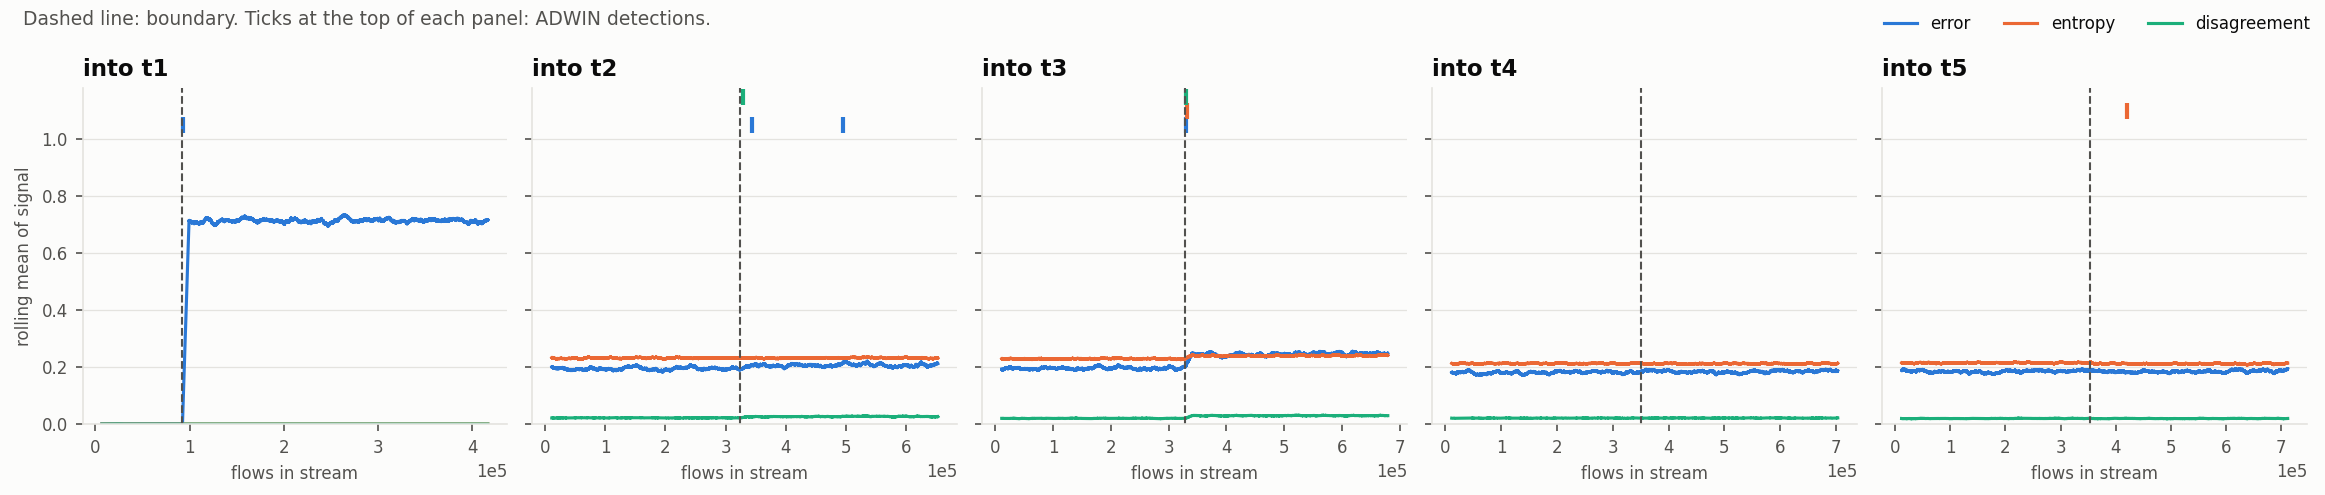

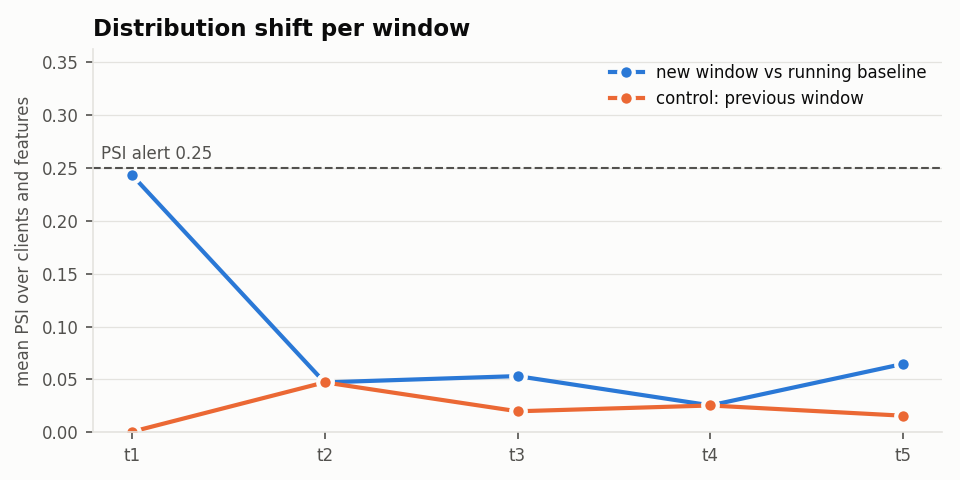

## Gate

Thresholds were tuned on the validation rows M3 held out, averaged over the models for t1 to t5, for the most errors captured within an escalation budget. The proposal sets no budget, so 10% is an assumption. **Used below: τc = 0.56, τd = 0.2.** Those rows set early stopping and calibration, so compare with the test rows below.

| escalation budget | τc | τd | escalation rate | errors captured |
|---:|---:|---:|---:|---:|
| 5% | 0.52 | 0.15 | 0.043 | 0.100 |
| 10% | 0.56 | 0.2 | 0.095 | 0.241 |
| 20% | 0.64 | 1.01 | 0.200 | 0.456 |
| 30% | 0.70 | 0.1 | 0.294 | 0.609 |

![frontier](escalation_vs_tau.png)

On the test sets. LLM calls count every flow; the other columns use CSV-only rows (D7). *Before update* is the old model on the new window; *settled* is the model after its update. The drift flag uses `disagreement` and holds for 200 flows after each rise.

| window | model | drift flag | LLM calls per 1k flows | errors sent to cloud | error rate among escalated | accuracy on the rest | unseen-class rows escalated |
|---|---|---|---:|---:|---:|---:|---:|
| t1 | settled | no | 104 | 0.252 | 0.473 | 0.831 | n/a |
| t1 | before update | no | 0 | 0.000 | 0.667 | 0.259 | 0.000 |
| t1 | before update | yes | 0 | 0.000 | 0.667 | 0.259 | 0.000 |
| t2 | settled | no | 97 | 0.262 | 0.532 | 0.833 | n/a |
| t2 | before update | no | 111 | 0.277 | 0.513 | 0.825 | 0.523 |
| t2 | before update | yes | 115 | 0.280 | 0.504 | 0.825 | 0.527 |
| t3 | settled | no | 90 | 0.244 | 0.494 | 0.844 | n/a |
| t3 | before update | no | 118 | 0.308 | 0.645 | 0.800 | 0.462 |
| t3 | before update | yes | 124 | 0.313 | 0.624 | 0.800 | 0.467 |
| t4 | settled | no | 88 | 0.238 | 0.501 | 0.839 | n/a |
| t4 | before update | no | 90 | 0.246 | 0.502 | 0.841 | 0.252 |
| t4 | before update | yes | 90 | 0.246 | 0.502 | 0.841 | 0.252 |
| t5 | settled | no | 90 | 0.252 | 0.510 | 0.843 | n/a |
| t5 | before update | no | 87 | 0.237 | 0.502 | 0.838 | n/a |
| t5 | before update | yes | 88 | 0.238 | 0.500 | 0.838 | n/a |

Every ADWIN and distribution event is in the run's `drift_registry.jsonl`; `adwin_streams.csv` and `distribution_shift.csv` hold the per-stream and per-feature numbers.


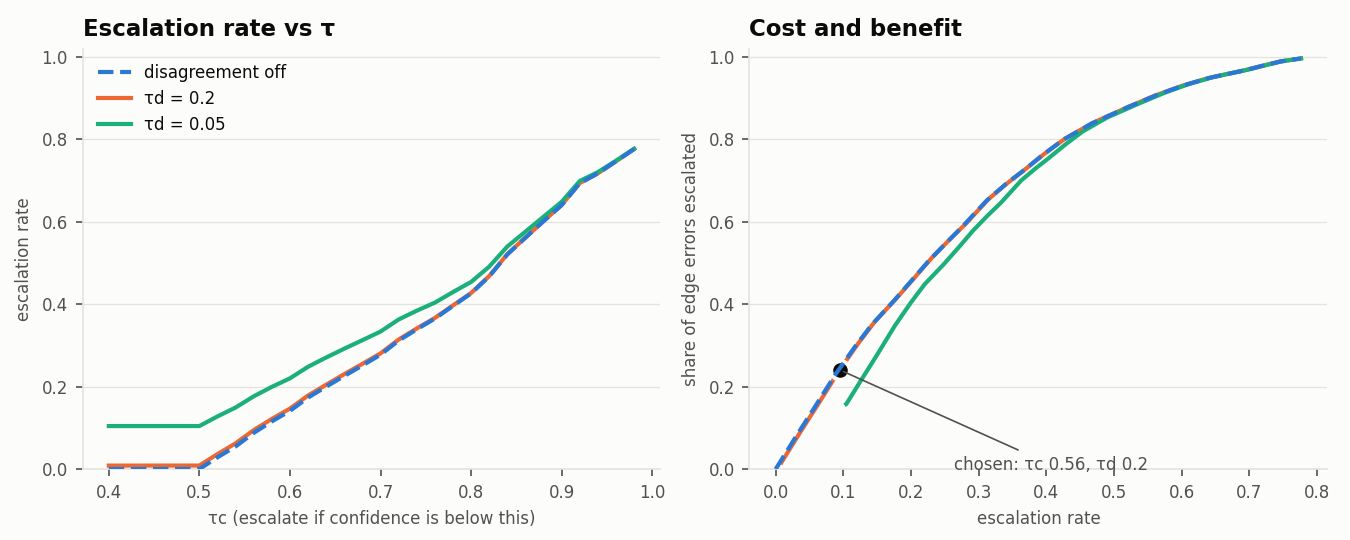

In [7]:
section("m5/full/DRIFT.md", "ADWIN summary")
fig("m5/full/signal_traces.png")
fig("m5/full/psi_by_window.png")
section("m5/full/DRIFT.md", "Gate")
fig("m5/full/escalation_vs_tau.png")

## M6: Incremental local learning and rehearsal buffer

## Results

| method | window avg | avg excl. t0 | final (t5) | class forgetting |
|---|---:|---:|---:|---:|
| Naive incremental | 0.9211 | 0.9054 | 0.8978 | 0.0242 |
| Local + rehearsal (2,000) | 0.9209 | 0.9052 | 0.8971 | 0.0218 |
| Local + rehearsal (500) | 0.9209 | 0.9052 | 0.8966 | 0.0233 |
| Local + rehearsal (8,000) | 0.9208 | 0.9051 | 0.8966 | 0.0192 |
| Retrain per client | 0.9205 | 0.9046 | 0.8930 | 0.0168 |
| E1 centralized (M3) | 0.8897 | 0.8677 | 0.8668 | 0.0277 |
| Static centralized (M3) | 0.4024 | 0.2829 | 0.1840 | n/a |

![curves](macro_f1_by_window.png)



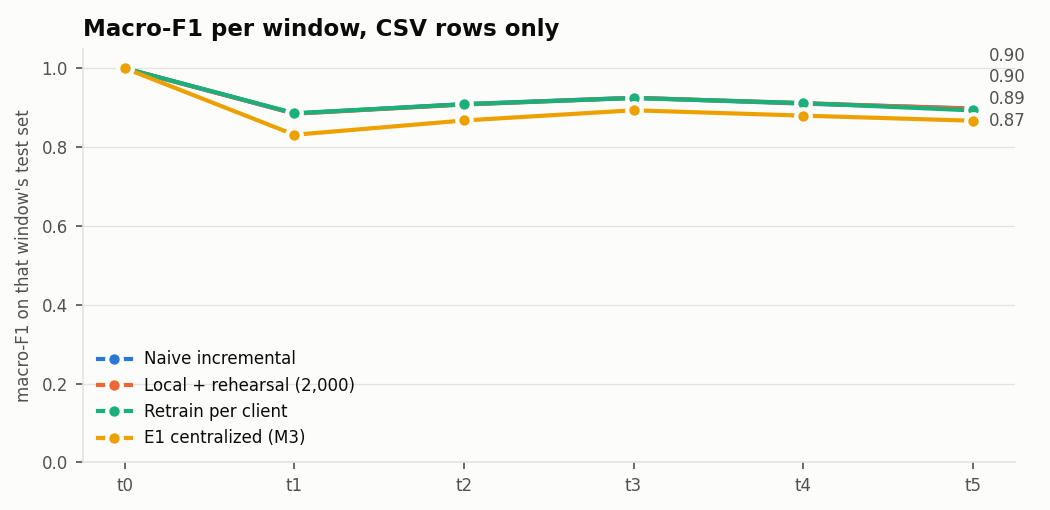

In [8]:
section("m6/full/INCREMENTAL.md", "Results")
fig("m6/full/macro_f1_by_window.png")

## M7: DA-FedDistill (E3, proposed method)

# M7 across seeds (`full` pool)

Generated by `scripts/m7_seeds.py` from 3 runs. Mean ± sample standard deviation. The seed changes model fitting, validation rows, buffer sampling and the calibrator's sample; the partition stays fixed.

| method | window avg | final (t5) | class forgetting | window avg minus local_rehearsal, per seed | final minus local_rehearsal, per seed |
|---|---:|---:|---:|---:|---:|
| local_rehearsal | 0.9207 ± 0.0004 | 0.8962 ± 0.0008 | 0.0218 ± 0.0008 | +0.0000, +0.0000, +0.0000 | +0.0000, +0.0000, +0.0000 |
| e3 | 0.9256 ± 0.0004 | 0.8947 ± 0.0010 | 0.0288 ± 0.0040 | +0.0049, +0.0043, +0.0057 | -0.0019, -0.0008, -0.0017 |
| e3_reliability | 0.9248 ± 0.0003 | 0.8949 ± 0.0006 | 0.0267 ± 0.0034 | +0.0041, +0.0036, +0.0049 | -0.0022, -0.0008, -0.0010 |
| e3_unweighted | 0.9220 ± 0.0004 | 0.9003 ± 0.0005 | 0.0063 ± 0.0032 | +0.0006, +0.0014, +0.0019 | +0.0036, +0.0034, +0.0053 |
| e3_no_drift | 0.9231 ± 0.0010 | 0.8951 ± 0.0006 | 0.0211 ± 0.0024 | +0.0029, +0.0012, +0.0033 | -0.0010, -0.0015, -0.0006 |
| e3_q8 | 0.9257 ± 0.0001 | 0.8961 ± 0.0002 | 0.0263 ± 0.0038 | +0.0047, +0.0050, +0.0054 | -0.0008, -0.0004, +0.0008 |
| e3_guard | 0.9285 ± 0.0005 | 0.9004 ± 0.0007 | 0.0237 ± 0.0011 | +0.0080, +0.0076, +0.0078 | +0.0033, +0.0049, +0.0045 |
| fedmd | 0.8873 ± 0.0002 | 0.8603 ± 0.0003 | 0.0318 ± 0.0009 | -0.0337, -0.0333, -0.0329 | -0.0369, -0.0358, -0.0349 |
| naive_incremental | 0.9212 ± 0.0001 | 0.8978 ± 0.0004 | 0.0251 ± 0.0008 | +0.0001, +0.0005, +0.0010 | +0.0009, +0.0019, +0.0021 |


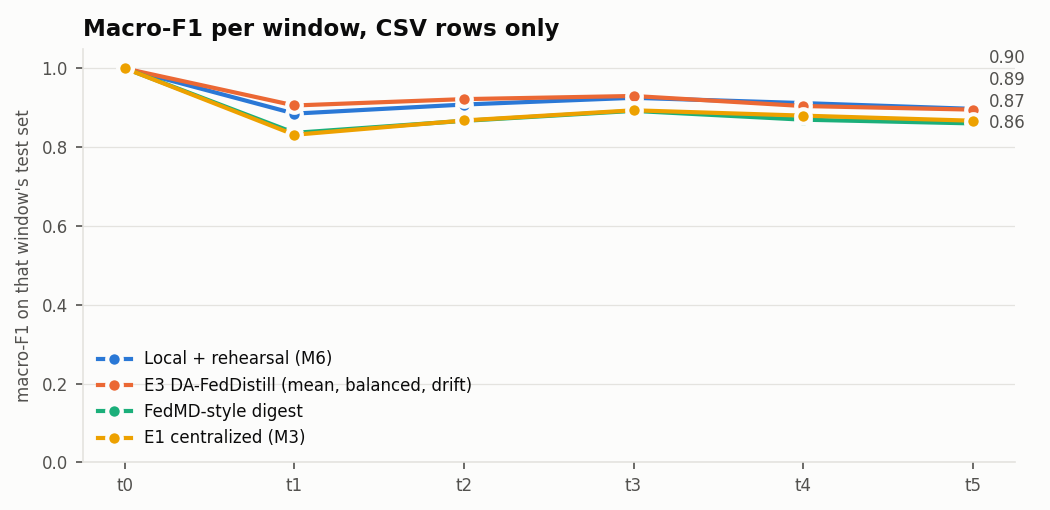

## Communication per client per round

15 clients, 6 rounds. Whole run: E3 sends 338.6 MB up as float32 and 16.6 MB as 8-bit + zlib, and 35.3 kB down. FedMD sends 8.2 MB up and 10.1 MB down (8-bit + zlib). The 8-bit uplink's accuracy is the `E3, 8-bit uplink` row above. g_t adds about 0.9 µs per flow at inference, batched.

| through | public rows | E3 up, float32 (MB) | E3 up, 8-bit (MB) | E3 up, 8-bit + zlib (MB) | E3 down (bytes) | FedMD up, 8-bit + zlib (MB) | FedMD down, 8-bit + zlib (MB) |
|---|---:|---:|---:|---:|---:|---:|---:|
| t0 | 27,222 | 1.307 | 0.327 | 0.007 | 392 | 0.000 | 0.001 |
| t1 | 85,681 | 4.113 | 1.028 | 0.206 | 392 | 0.099 | 0.120 |
| t2 | 86,737 | 4.163 | 1.041 | 0.214 | 392 | 0.108 | 0.133 |
| t3 | 90,004 | 4.320 | 1.080 | 0.222 | 392 | 0.112 | 0.139 |
| t4 | 90,182 | 4.329 | 1.082 | 0.223 | 392 | 0.112 | 0.139 |
| t5 | 90,429 | 4.341 | 1.085 | 0.234 | 392 | 0.117 | 0.141 |



In [9]:
display(Markdown((R / "m7/full/SEEDS.md").read_text(encoding="utf-8")))
fig("m7/full/macro_f1_by_window.png")
section("m7/full/DISTILL.md", "Communication per client per round")

## M8: Neural FL baselines (FedAvg / FedProx MLP, E2)

# M8 across seeds (`full` pool)

Generated by `scripts/m7_seeds.py` from 3 runs. Mean ± sample standard deviation. The seed changes model fitting, validation rows, buffer sampling and the calibrator's sample; the partition stays fixed.

| method | window avg | final (t5) | class forgetting | window avg minus e3, per seed | final minus e3, per seed |
|---|---:|---:|---:|---:|---:|
| fedavg | 0.8415 ± 0.0039 | 0.7811 ± 0.0014 | 0.0697 ± 0.0018 | -0.0803, -0.0838, -0.0882 | -0.1123, -0.1149, -0.1136 |
| fedavg_static | 0.3735 ± 0.0057 | 0.1373 ± 0.0081 | n/a | -0.5571, -0.5532, -0.5461 | -0.7640, -0.7612, -0.7472 |
| fedavg_no_rehearsal | 0.8452 ± 0.0031 | 0.7908 ± 0.0053 | 0.0643 ± 0.0090 | -0.0773, -0.0826, -0.0813 | -0.0981, -0.1071, -0.1064 |
| fedprox | 0.8414 ± 0.0025 | 0.7800 ± 0.0023 | 0.0736 ± 0.0091 | -0.0848, -0.0811, -0.0868 | -0.1141, -0.1137, -0.1163 |
| fedprox_static | 0.3732 ± 0.0058 | 0.1369 ± 0.0080 | n/a | -0.5577, -0.5532, -0.5464 | -0.7645, -0.7611, -0.7478 |
| fedprox_mu0.001 | 0.8391 ± 0.0043 | 0.7779 ± 0.0035 | 0.0784 ± 0.0050 | -0.0888, -0.0811, -0.0896 | -0.1179, -0.1137, -0.1187 |
| fedprox_mu0.01 | 0.8393 ± 0.0016 | 0.7796 ± 0.0020 | 0.0693 ± 0.0021 | -0.0848, -0.0874, -0.0868 | -0.1141, -0.1149, -0.1163 |
| fedprox_mu0.1 | 0.8252 ± 0.0017 | 0.7659 ± 0.0024 | 0.0868 ± 0.0041 | -0.1005, -0.0983, -0.1025 | -0.1263, -0.1311, -0.1292 |
| fedprox_mu1 | 0.8112 ± 0.0012 | 0.7503 ± 0.0031 | 0.0820 ± 0.0066 | -0.1159, -0.1135, -0.1137 | -0.1447, -0.1421, -0.1465 |
| local_rehearsal | 0.9207 ± 0.0004 | 0.8962 ± 0.0008 | 0.0218 ± 0.0008 | -0.0049, -0.0043, -0.0057 | +0.0019, +0.0008, +0.0017 |
| e3 | 0.9256 ± 0.0004 | 0.8947 ± 0.0010 | 0.0288 ± 0.0040 | +0.0000, +0.0000, +0.0000 | +0.0000, +0.0000, +0.0000 |
| e3_guard | 0.9285 ± 0.0005 | 0.9004 ± 0.0007 | 0.0237 ± 0.0011 | +0.0031, +0.0032, +0.0022 | +0.0052, +0.0057, +0.0062 |
| fedmd | 0.8873 ± 0.0002 | 0.8603 ± 0.0003 | 0.0318 ± 0.0009 | -0.0386, -0.0377, -0.0386 | -0.0350, -0.0350, -0.0331 |
| naive_incremental | 0.9212 ± 0.0001 | 0.8978 ± 0.0004 | 0.0251 ± 0.0008 | -0.0048, -0.0038, -0.0047 | +0.0029, +0.0027, +0.0039 |


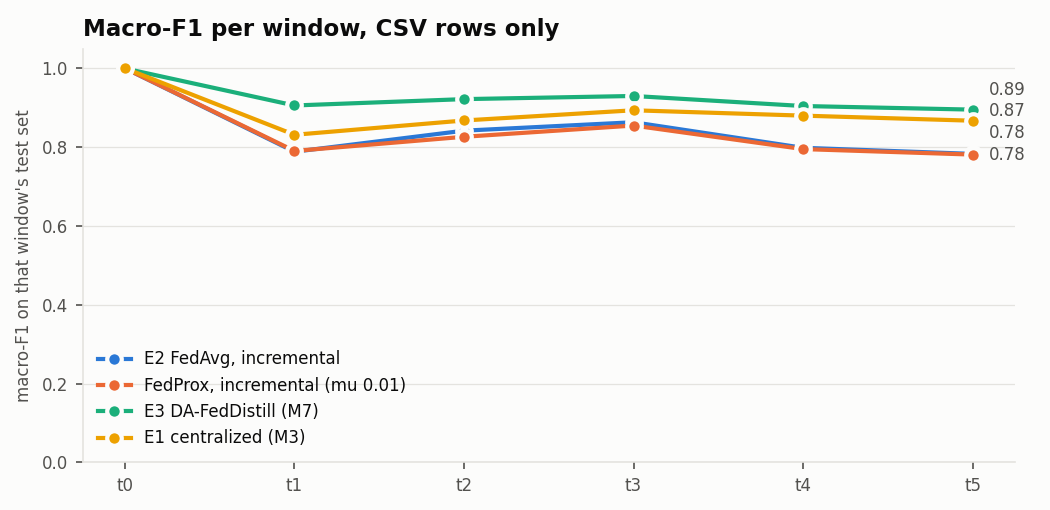

In [10]:
display(Markdown((R / "m8/full/SEEDS.md").read_text(encoding="utf-8")))
fig("m8/full/macro_f1_by_window.png")

## M9: Drift-triggered updates, top-K features, adaptive threshold (E4)

# M9 across seeds (`full` pool)

Generated by `scripts/m7_seeds.py` from 3 runs. Mean ± sample standard deviation. The seed changes model fitting, validation rows, buffer sampling and the calibrator's sample; the partition stays fixed.

| method | window avg | final (t5) | class forgetting | window avg minus e3, per seed | final minus e3, per seed |
|---|---:|---:|---:|---:|---:|
| fixed | 0.9254 ± 0.0003 | 0.8940 ± 0.0009 | 0.0291 ± 0.0031 | -0.0003, -0.0000, -0.0002 | -0.0011, -0.0006, -0.0005 |
| fixed_guard | 0.9285 ± 0.0003 | 0.9003 ± 0.0007 | 0.0243 ± 0.0011 | +0.0029, +0.0035, +0.0023 | +0.0049, +0.0057, +0.0063 |
| fixed_local | 0.9206 ± 0.0004 | 0.8959 ± 0.0011 | 0.0220 ± 0.0004 | -0.0050, -0.0043, -0.0057 | +0.0018, +0.0007, +0.0009 |
| fixed_k10 | 0.9151 ± 0.0010 | 0.8799 ± 0.0037 | 0.0284 ± 0.0018 | -0.0102, -0.0093, -0.0119 | -0.0137, -0.0129, -0.0179 |
| fixed_k10_guard | 0.9174 ± 0.0011 | 0.8842 ± 0.0033 | 0.0283 ± 0.0010 | -0.0075, -0.0074, -0.0097 | -0.0090, -0.0092, -0.0132 |
| fixed_k10_local | 0.9113 ± 0.0001 | 0.8812 ± 0.0017 | 0.0249 ± 0.0005 | -0.0146, -0.0138, -0.0146 | -0.0126, -0.0135, -0.0144 |
| fixed_k20 | 0.9223 ± 0.0007 | 0.8894 ± 0.0004 | 0.0270 ± 0.0033 | -0.0044, -0.0025, -0.0031 | -0.0053, -0.0060, -0.0048 |
| fixed_k20_guard | 0.9249 ± 0.0011 | 0.8945 ± 0.0012 | 0.0257 ± 0.0015 | -0.0022, +0.0003, -0.0004 | -0.0013, +0.0003, +0.0003 |
| fixed_k20_local | 0.9177 ± 0.0003 | 0.8900 ± 0.0011 | 0.0229 ± 0.0004 | -0.0084, -0.0072, -0.0082 | -0.0052, -0.0044, -0.0045 |
| fixed_k30 | 0.9255 ± 0.0008 | 0.8950 ± 0.0007 | 0.0282 ± 0.0014 | +0.0006, -0.0001, -0.0007 | +0.0006, -0.0013, +0.0016 |
| fixed_k30_guard | 0.9285 ± 0.0006 | 0.9004 ± 0.0010 | 0.0229 ± 0.0026 | +0.0032, +0.0032, +0.0021 | +0.0057, +0.0057, +0.0057 |
| fixed_k30_local | 0.9208 ± 0.0002 | 0.8966 ± 0.0003 | 0.0221 ± 0.0001 | -0.0051, -0.0042, -0.0053 | +0.0017, +0.0014, +0.0027 |
| e4_schedule | 0.8583 ± 0.0241 | 0.7714 ± 0.0192 | 0.0078 ± 0.0158 | -0.0570, -0.0945, -0.0505 | -0.1145, -0.1461, -0.1092 |
| e4_schedule_guard | 0.8993 ± 0.0018 | 0.8459 ± 0.0053 | -0.0149 ± 0.0129 | -0.0274, -0.0272, -0.0245 | -0.0471, -0.0557, -0.0437 |
| e4_schedule_local | 0.8874 ± 0.0016 | 0.8409 ± 0.0045 | -0.0191 ± 0.0126 | -0.0399, -0.0378, -0.0368 | -0.0522, -0.0597, -0.0495 |
| e4_label_free | 0.7640 ± 0.0003 | 0.7527 ± 0.0008 | 0.0249 ± 0.0003 | -0.1621, -0.1613, -0.1616 | -0.1414, -0.1435, -0.1411 |
| e4_label_free_guard | 0.8068 ± 0.0087 | 0.8462 ± 0.0257 | -0.0121 ± 0.0017 | -0.1140, -0.1284, -0.1141 | -0.0340, -0.0790, -0.0327 |
| e4_label_free_local | 0.8039 ± 0.0090 | 0.8417 ± 0.0266 | -0.0154 ± 0.0017 | -0.1167, -0.1317, -0.1168 | -0.0381, -0.0846, -0.0365 |
| e4 | 0.8538 ± 0.0219 | 0.8378 ± 0.0157 | -0.0560 ± 0.0098 | -0.0840, -0.0846, -0.0468 | -0.0419, -0.0569, -0.0719 |
| e4_guard | 0.9048 ± 0.0042 | 0.8733 ± 0.0153 | -0.0220 ± 0.0182 | -0.0226, -0.0157, -0.0243 | -0.0091, -0.0177, -0.0373 |
| e4_local | 0.8952 ± 0.0050 | 0.8705 ± 0.0174 | -0.0264 ± 0.0173 | -0.0316, -0.0246, -0.0351 | -0.0116, -0.0181, -0.0430 |
| e4_added | 0.9241 ± 0.0004 | 0.8920 ± 0.0020 | 0.0302 ± 0.0015 | -0.0015, -0.0016, -0.0015 | -0.0026, -0.0057, +0.0001 |
| e4_added_guard | 0.9268 ± 0.0004 | 0.8984 ± 0.0024 | 0.0249 ± 0.0009 | +0.0006, +0.0018, +0.0013 | +0.0023, +0.0012, +0.0075 |
| e4_added_local | 0.9200 ± 0.0004 | 0.8954 ± 0.0010 | 0.0222 ± 0.0004 | -0.0061, -0.0053, -0.0054 | +0.0006, -0.0011, +0.0027 |
| local_rehearsal | 0.9207 ± 0.0004 | 0.8962 ± 0.0008 | 0.0218 ± 0.0008 | -0.0049, -0.0043, -0.0057 | +0.0019, +0.0008, +0.0017 |
| e3 | 0.9256 ± 0.0004 | 0.8947 ± 0.0010 | 0.0288 ± 0.0040 | +0.0000, +0.0000, +0.0000 | +0.0000, +0.0000, +0.0000 |
| e3_guard | 0.9285 ± 0.0005 | 0.9004 ± 0.0007 | 0.0237 ± 0.0011 | +0.0031, +0.0032, +0.0022 | +0.0052, +0.0057, +0.0062 |


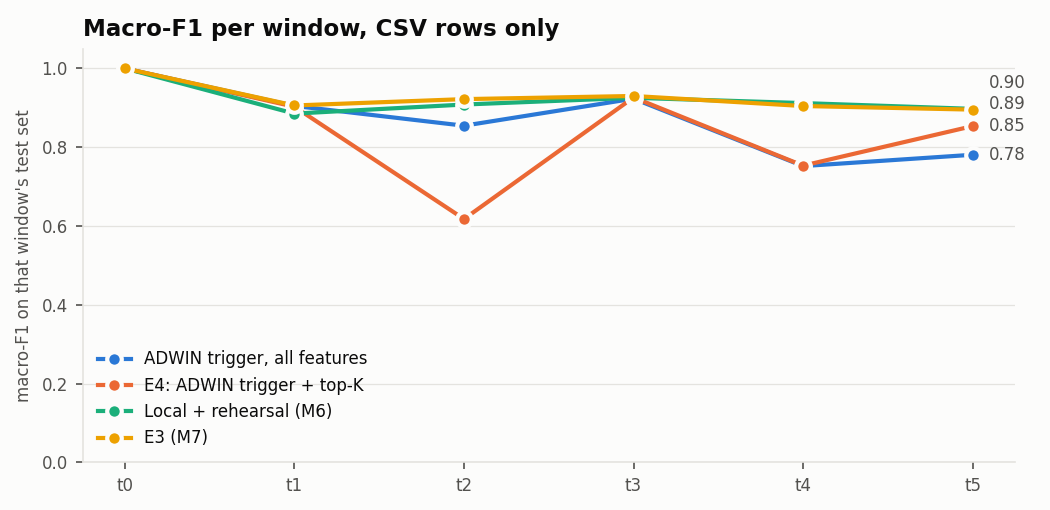

In [11]:
display(Markdown((R / "m9/full/SEEDS.md").read_text(encoding="utf-8")))
fig("m9/full/macro_f1_by_window.png")

## M10: SHAP explainability

## SHAP drift signal

The model through t−1, before any update, explained on window t's rows and compared with its explanation on window t−1's rows (1 − Spearman ρ of mean |SHAP|, and the share of the top features kept). The control compares two disjoint samples of window t−1, so it is the noise floor. Mean over clients.

| boundary | change, new window | change, control | top-5 kept, new window | top-5 kept, control | share of clients above their control |
|---|---:|---:|---:|---:|---:|
| t0 → t1 | 0.015 | 0.004 | 0.96 | 0.99 | 0.93 |
| t1 → t2 | 0.004 | 0.001 | 0.97 | 1.00 | 0.53 |
| t2 → t3 | 0.010 | 0.001 | 0.93 | 0.96 | 0.87 |
| t3 → t4 | 0.002 | 0.002 | 0.95 | 0.95 | 0.53 |
| t4 → t5 | 0.012 | 0.002 | 0.87 | 0.96 | 0.60 |

![drift](shap_drift.png)



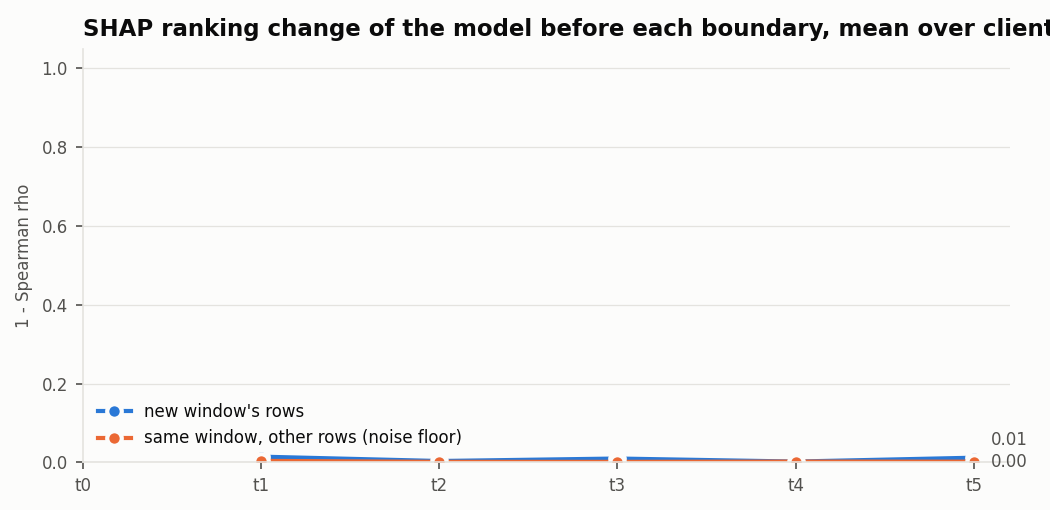

## Global ranking (cloud: mean over clients of mean |SHAP|), top 10

| rank | t0 | t1 | t2 | t3 | t4 | t5 |
|---|---|---|---|---|---|---|
| 1 | `Number` | `Number` | `Number` | `Number` | `Number` | `Number` |
| 2 | `AVG` | `Header_Length` | `Header_Length` | `rst_count` | `rst_count` | `Header_Length` |
| 3 | `Tot_size` | `Rate` | `Rate` | `Header_Length` | `Header_Length` | `rst_count` |
| 4 | `Variance` | `Srate` | `Srate` | `Rate` | `Rate` | `Rate` |
| 5 | `Srate` | `AVG` | `rst_count` | `Variance` | `Srate` | `Srate` |
| 6 | `syn_flag_number` | `Variance` | `syn_count` | `Srate` | `Variance` | `Variance` |
| 7 | `Min` | `Protocol_Type` | `AVG` | `AVG` | `Tot_size` | `fin_count` |
| 8 | `Covariance` | `syn_count` | `Protocol_Type` | `Tot_size` | `AVG` | `Tot_size` |
| 9 | `ack_flag_number` | `Tot_size` | `Variance` | `syn_count` | `Magnitue` | `AVG` |
| 10 | `ICMP` | `UDP` | `Tot_size` | `Magnitue` | `syn_count` | `syn_count` |

Stores: `local.parquet` (top features per row), `global_by_client.csv`, `global.csv`, `shap_drift.csv`, `cost.csv`.


In [12]:
section("m10/full/SHAP.md", "SHAP drift signal")
fig("m10/full/shap_drift.png")
section("m10/full/SHAP.md", "Global ranking")

## M11: Cloud LLM verifier (E5, E6)

In [13]:
section("m11/full/VERIFY.md")
section("m11/full/VERIFY.md", "Mean over windows")

# M11: LLM verification of E4 (`e4_added`, D11), `full` pool

Seed 42. Generated by `scripts/m11_verify.py`. Verifier: **/kaggle/input/models/google/gemma-2/transformers/gemma-2-2b-it/2**. Gate: E4's, adaptive strength 8 (README, M11).

**Models against M9:** the rerun `e4_added` (K = 30) differs from M9's report by at most 0.000445 macro-F1 in any window.

**Rows:** 82,500 sampled, 14,067 sent to the verifier. **Valid replies:** 0.5543 on the first try, 0.9999 after retries (1 fallbacks). **Grounded** (every reason names a feature or class from the evidence): 0.967 of valid replies.
**Payload:** 1020 bytes on average. **Batch latency:** mean 24338 ms, P95 27609 ms; 0.66 rows per second.
**LLM calls per 1k rows (E5, full stream):** boundary 84.1, own window 75.3; E6: 1000.

**On escalated rows:** the verifier's label is right on 0.400 of them and the edge's on 0.537. The verifier disagrees with the edge on 0.503, and D3 allows the change on 0.098.



## Mean over windows

| rows | setting | method | macro-F1 | false-positive rate | miss rate |
|---|---|---|---:|---:|---:|
| always_on | boundary | E5 gated, D3 | 0.6800 | 0.0125 | 0.0033 |
| always_on | boundary | E6 always-on, D3 | 0.6792 | 0.0125 | 0.0033 |
| always_on | boundary | always-on, LLM label whenever valid | 0.4906 | 0.0125 | 0.0033 |
| always_on | boundary | E4 edge | 0.6819 | 0.0125 | 0.0033 |
| always_on | own window | E5 gated, D3 | 0.9197 | 0.0370 | 0.0005 |
| always_on | own window | E6 always-on, D3 | 0.9185 | 0.0370 | 0.0005 |
| always_on | own window | always-on, LLM label whenever valid | 0.6896 | 0.0370 | 0.0005 |
| always_on | own window | E4 edge | 0.9212 | 0.0370 | 0.0005 |
| sample | boundary | E5 gated, D3 | 0.6763 | 0.0155 | 0.0039 |
| sample | boundary | gated, LLM label whenever valid | 0.6736 | 0.0155 | 0.0039 |
| sample | boundary | E4 edge | 0.6776 | 0.0155 | 0.0039 |
| sample | own window | E5 gated, D3 | 0.9309 | 0.0193 | 0.0005 |
| sample | own window | gated, LLM label whenever valid | 0.9287 | 0.0193 | 0.0005 |
| sample | own window | E4 edge | 0.9316 | 0.0193 | 0.0005 |

`sample`: up to the configured rows per client and window; `always_on`: the first rows of that sample, every one sent to the verifier. `boundary`: the model through t−1 on window t's rows (H3's high-drift setting); `own window`: the model on its own window.



## M12: LLM adaptation-policy agent (seeds 42, 43 and 44)

In [14]:
section("m12/full/POLICY.md")
section("m12/full/POLICY.md", "Decisions, llm arm")

# three seeds side by side
seeds = (("seed 42", ""), ("seed 43", "seed43/"), ("seed 44", "seed44/"))
arms = {s: json.loads((R / f"m12/full/{d}summary.json").read_text())["arms"] for s, d in seeds}
m12_tab = pd.DataFrame({(arm, s): {"window avg": a[arm]["window_avg_macro_f1"], "final": a[arm]["final_macro_f1"],
                                   "next-window avg": a[arm]["next_window_avg"]}
                        for s, a in arms.items() for arm in a}).T
display(m12_tab.groupby(level=0).agg(["mean", "std"]).round(4))

# M12: adaptation-policy agent on E4 (`e4_added`), `full` pool

Seed 42. Generated by `scripts/m12_policy.py`. Policy backend for the llm arm: **/kaggle/input/models/google/gemma-2/transformers/gemma-2-2b-it/2**.

**The none arm against M9's `e4_added`:** largest difference 0.001094 macro-F1 per window.

| arm | window avg | avg excl. t0 | final | next-window avg | class forgetting |
|---|---:|---:|---:|---:|---:|
| none | 0.9241 | 0.9090 | 0.8915 | 0.6635 | 0.0286 |
| heuristic | 0.9241 | 0.9090 | 0.8910 | 0.6667 | 0.0264 |
| llm | 0.8218 | 0.7863 | 0.7498 | 0.5970 | 0.0206 |

| arm | t0 | t1 | t2 | t3 | t4 | t5 |
|---|---:|---:|---:|---:|---:|---:|
| none | 0.9994 | 0.9018 | 0.9205 | 0.9298 | 0.9015 | 0.8915 |
| heuristic | 0.9994 | 0.9043 | 0.9193 | 0.9275 | 0.9032 | 0.8910 |
| llm | 0.9994 | 0.8854 | 0.6206 | 0.9248 | 0.7510 | 0.7498 |



## Decisions, llm arm

75 decisions (0.53 at an ADWIN trigger); valid 1.000, first try 0.800; mean 10.5 s per decision.

- `update_urgency`: low 1.00
- `training_style`: conservative 1.00
- `preserve_old_behavior`: True 1.00
- `buffer_selection`: uniform 1.00
- `update_scope`: partial 1.00
- `feature_focus_groups`: rate_timing 70, packet_size 70, tcp_flags 5, protocol 5

**llm and heuristic arms, same decision on** 0.000 of decision points (meaningful while both arms reach the same points).

Stores: `arm_<arm>.json`, `decisions_<arm>.jsonl` (each decision with its evidence), `llm_log_llm.jsonl` (every prompt and reply).


window avg           final         next-window avg        
                mean     std    mean     std            mean     std
heuristic     0.9234  0.0006  0.8893  0.0014          0.6636  0.0027
llm           0.8252  0.0029  0.7595  0.0213          0.5997  0.0047
none          0.9241  0.0005  0.8916  0.0022          0.6641  0.0019

## M13: Federated GBDT baseline (E7)

# M13: E7, horizontal federated GBDT (`full` pool)

Run `20261115-144312_m13_fedgbdt_full`, seed 42. Generated by `scripts/m13_fedgbdt.py`. Scores use CSV-only rows (D7); E7 is one global model.
References are read from the earlier milestones' reports for the same pool (seed 42).

| method | window avg | avg excl. t0 | final | class forgetting |
|---|---:|---:|---:|---:|
| **E7 federated GBDT** | 0.8814 | 0.8577 | 0.8525 | 0.0323 |
| E1 centralized (M3) | 0.8897 | 0.8677 | 0.8668 | 0.0277 |
| Naive incremental, local (M6) | 0.9211 | 0.9054 | 0.8978 | 0.0242 |
| E3 DA-FedDistill (M7) | 0.9258 | 0.9111 | 0.8950 | 0.0247 |
| E4 (M9, e4_added) | 0.9243 | 0.9093 | 0.8924 | 0.0291 |

| method | t0 | t1 | t2 | t3 | t4 | t5 |
|---|---:|---:|---:|---:|---:|---:|
| **E7** | 1.000 | 0.823 | 0.862 | 0.888 | 0.862 | 0.852 |
| E1 centralized (M3) | 1.000 | 0.831 | 0.867 | 0.893 | 0.880 | 0.867 |
| Naive incremental, local (M6) | 1.000 | 0.885 | 0.909 | 0.925 | 0.910 | 0.898 |
| E3 DA-FedDistill (M7) | 0.999 | 0.905 | 0.922 | 0.930 | 0.904 | 0.895 |
| E4 (M9, e4_added) | 0.999 | 0.902 | 0.921 | 0.929 | 0.902 | 0.892 |

![curves](macro_f1_by_window.png)



## Cost

Uplink: an upper bound per client, one gradient and one Hessian histogram (8-byte values, all bins) per new tree node, without XGBoost's subtraction trick, which halves it; the quantile sketch isn't counted. E3's is its raw float32 soft labels on D_pub (M7).

| window | clients | rounds added | fit seconds | model MB | E7 uplink per client (MB) | E3 uplink per client (MB) |
|---|---:|---:|---:|---:|---:|---:|
| t0 | 15 | 50 | 71 | 0.39 | 998.3 | 1.31 |
| t1 | 15 | 50 | 115 | 2.08 | 7721.8 | 4.11 |
| t2 | 15 | 50 | 131 | 3.67 | 7238.5 | 4.16 |
| t3 | 15 | 50 | 166 | 6.08 | 11438.1 | 4.32 |
| t4 | 15 | 50 | 194 | 8.85 | 13348.7 | 4.33 |
| t5 | 15 | 50 | 204 | 11.73 | 13877.5 | 4.34 |

Stores: `summary.json`, `results.csv`, `per_class.csv`, `confusions.csv`, `cost.csv`.


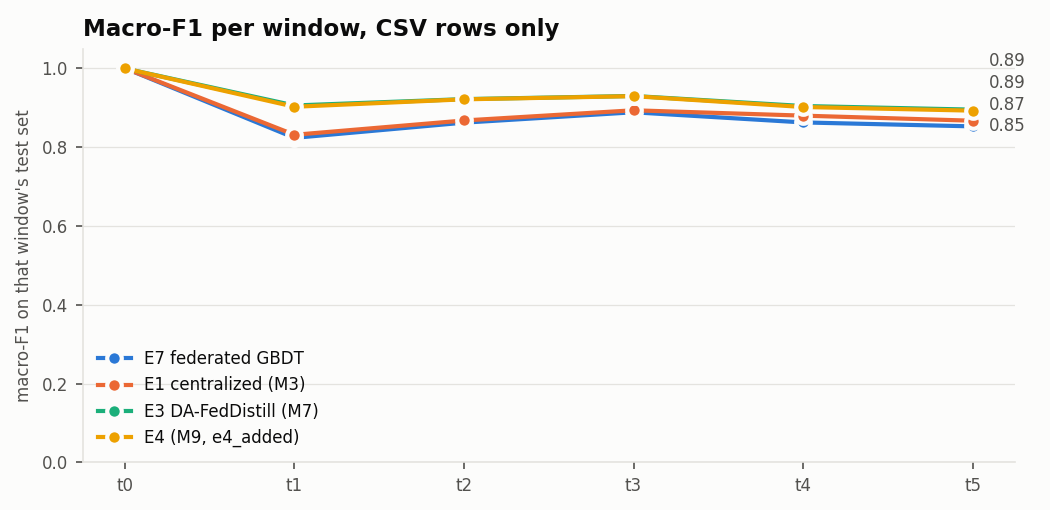

In [15]:
section("m13/full/FEDGBDT.md")
section("m13/full/FEDGBDT.md", "Cost")
fig("m13/full/macro_f1_by_window.png")

## M14: Full experiment matrix, ablations and sensitivity

Three seeds (42, 43, 44) for the headline, paired client-bootstrap intervals with Holm correction, ablations on E4, ten sensitivity variants at seed 42, and the gate frontier. Read from `reports/m14/full/REPORT.md`.

In [16]:
for h in ("Headline", "Hypotheses", "Sensitivity"):
    section("m14/full/REPORT.md", h)

## Headline

| method | window avg (mean ± std over seeds) | 95% interval, seed mean | t5 (mean ± std) |
|---|---:|---:|---:|
| E1 centralized | 0.8897 ± 0.0001 | 0.8720 to 0.9020 | 0.8669 ± 0.0004 |
| static | 0.3957 ± 0.0058 | 0.3611 to 0.4225 | 0.1740 ± 0.0087 |
| naive incremental | 0.9212 ± 0.0001 | 0.9024 to 0.9337 | 0.8978 ± 0.0004 |
| local + rehearsal | 0.9208 ± 0.0003 | 0.9018 to 0.9332 | 0.8967 ± 0.0006 |
| E2 FedAvg | 0.8415 ± 0.0039 | 0.8194 to 0.8583 | 0.7811 ± 0.0014 |
| E2 FedProx | 0.8414 ± 0.0025 | 0.8191 to 0.8585 | 0.7800 ± 0.0023 |
| E3 | 0.9256 ± 0.0004 | 0.9108 to 0.9331 | 0.8947 ± 0.0010 |
| FedMD | 0.8873 ± 0.0002 | 0.8630 to 0.9053 | 0.8603 ± 0.0003 |
| e3_guard (addition) | 0.9285 ± 0.0005 | 0.9133 to 0.9362 | 0.9004 ± 0.0007 |
| E4 (e4_added) | 0.9241 ± 0.0004 | 0.9086 to 0.9319 | 0.8920 ± 0.0020 |
| e4 (ADWIN replaces schedule) | 0.8538 ± 0.0219 | 0.8316 to 0.8648 | 0.8378 ± 0.0157 |
| E7 federated GBDT | 0.8814 ± 0.0000 | 0.8630 to 0.8940 | 0.8514 ± 0.0009 |

E5 and E6 are scored on M11's sampled rows (500 per client and window; always-on: the first 50 of them), so they are compared with the E4 edge on the same rows, not with the table above.

| rows | setting | method | macro-F1 (mean ± std) | benign false-positive rate (mean ± std) |
|---|---|---|---:|---:|
| sample | boundary | E4 edge | 0.6737 ± 0.0074 | 0.0211 ± 0.0098 |
| always_on | boundary | E4 edge | 0.6731 ± 0.0115 | 0.0164 ± 0.0074 |
| sample | own window | E4 edge | 0.9295 ± 0.0030 | 0.0257 ± 0.0061 |
| always_on | own window | E4 edge | 0.9251 ± 0.0091 | 0.0260 ± 0.0164 |
| sample | boundary | E5 gated | 0.6726 ± 0.0076 | 0.0211 ± 0.0098 |
| always_on | boundary | E5 gated | 0.6722 ± 0.0109 | 0.0164 ± 0.0074 |
| sample | own window | E5 gated | 0.9288 ± 0.0031 | 0.0257 ± 0.0061 |
| always_on | own window | E5 gated | 0.9242 ± 0.0095 | 0.0260 ± 0.0164 |
| always_on | boundary | E6 always-on | 0.6711 ± 0.0108 | 0.0164 ± 0.0074 |
| always_on | own window | E6 always-on | 0.9236 ± 0.0095 | 0.0260 ± 0.0164 |

LLM calls per 1k flows, E5 (full stream, boundary): 84.1, 84.3, 87.4; E6: 1000.



## Hypotheses (Holm over the five tests below)

| id | test | difference | 95% interval | p | Holm p | result |
|---|---|---:|---:|---:|---:|---|
| H1a | E3 minus naive incremental, window-avg macro-F1 | +0.00443 | -0.00236 to +0.00963 | 0.2174 | 0.6522 | no |
| H1b | E3 minus static, window-avg macro-F1 | +0.52990 | +0.50437 to +0.55779 | 0.0000 | 0.0000 | yes |
| H2a | E4 minus E3, variance of macro-F1 over t1-t5 (lower is better) | +0.00004 | +0.00000 to +0.00012 | 0.0294 | 0.1176 | no |
| H2b | E4 minus E3, mean time-to-recover in windows, eps 0.02 (lower is better) | +0.00000 | +0.00000 to +0.40000 | 1.0000 | 1.0000 | no |
| H3 | E5 gated minus E4 edge, benign false-positive rate, boundary windows t1-t5, sampled rows (lower is better) | +0.00000 | +0.00000 to +0.00000 | 1.0000 | 1.0000 | no |

Observed, seed-averaged: variance over t1-t5 E3 0.00018, E4 0.00022; mean time-to-recover E3 2.40, E4 2.40 windows (a drop that never recovers counts as one window past t5).



## Sensitivity (tier 2, seed 42; one run per variant, so the intervals are client intervals only)

| variant | clients | E1 | local + rehearsal | E3 | E4 | E3 − local (95% interval) | E4 − E3 (95% interval) |
|---|---:|---:|---:|---:|---:|---:|---:|
| headline (seed 42) | 15 | 0.8897 | 0.9209 | 0.9258 | 0.9243 | | |
| clients10 | 10 | 0.8897 | 0.9232 | 0.9272 | 0.9264 | +0.0039 (-0.0054 to +0.0098) | -0.0007 (-0.0033 to +0.0022) |
| clients20 | 20 | 0.8897 | 0.9208 | 0.9243 | 0.9209 | +0.0036 (-0.0018 to +0.0077) | -0.0035 (-0.0065 to -0.0009) |
| alpha0.1 | 15 | 0.8897 | 0.9573 | 0.7091 | 0.7211 | -0.2481 (-0.3162 to -0.1524) | +0.0120 (-0.0115 to +0.0391) |
| alpha1.0 | 15 | 0.8897 | 0.9041 | 0.9017 | 0.9007 | -0.0024 (-0.0038 to -0.0004) | -0.0010 (-0.0028 to +0.0004) |
| alt_order | 15 | 0.9179 | 0.9402 | 0.9347 | 0.9340 | -0.0055 (-0.0099 to -0.0027) | -0.0007 (-0.0046 to +0.0029) |
| reseed | 15 | 0.8895 | 0.9175 | 0.9158 | 0.9152 | -0.0017 (-0.0054 to +0.0008) | -0.0005 (-0.0029 to +0.0016) |
| with_iat | 15 | 0.9901 | 0.9914 | 0.9901 | 0.9894 | -0.0013 (-0.0028 to -0.0006) | -0.0007 (-0.0014 to -0.0002) |
| no_number_weight | 15 | 0.8896 | 0.9192 | 0.9243 | 0.9215 | +0.0050 (-0.0021 to +0.0101) | -0.0028 (-0.0057 to -0.0004) |
| no_profiling | 15 | 0.8894 | 0.9198 | 0.9253 | 0.9221 | +0.0055 (-0.0009 to +0.0101) | -0.0032 (-0.0052 to -0.0018) |
| official_split | 15 | 0.8423 | 0.8889 | 0.8928 | 0.8938 | +0.0039 (-0.0019 to +0.0083) | +0.0011 (-0.0025 to +0.0051) |

Tier 3 (τc/τd frontier, H4): `TIER3.md`, written by the same command.

![per window](macro_f1_by_window.png)


## M15: Reproducibility package

Notebooks A and B were rerun on Kaggle from a fresh clone and the public processed dataset, and compared with the committed seed-42 results (tolerance ±0.005 macro-F1).

In [17]:
for part in ("A", "B"):
    section(f"m15/full/CHECK_{part}.md")

# M15 check, part A (full pool, seed 42): PASS

56 cells against the files at `HEAD`; tolerance ±0.005; largest difference 0.001377; 0 outside the tolerance or missing.

| source | method | cell | committed | new | difference |
|---|---|---|---:|---:|---:|
| m4 | E1 | window_avg | 0.889688 | 0.889691 | 0.000002 |
| m4 | E1 | t0 | 0.999853 | 0.999853 | 0.000000 |
| m4 | E1 | t1 | 0.831104 | 0.831118 | 0.000014 |
| m4 | E1 | t2 | 0.867391 | 0.867391 | 0.000000 |
| m4 | E1 | t3 | 0.893268 | 0.893268 | 0.000000 |
| m4 | E1 | t4 | 0.879702 | 0.879702 | 0.000000 |
| m4 | E1 | t5 | 0.866813 | 0.866813 | 0.000000 |
| m4 | static | window_avg | 0.402428 | 0.402428 | 0.000000 |
| m4 | static | t0 | 0.999853 | 0.999853 | 0.000000 |
| m4 | static | t1 | 0.462590 | 0.462590 | 0.000000 |
| m4 | static | t2 | 0.323941 | 0.323941 | 0.000000 |
| m4 | static | t3 | 0.249789 | 0.249789 | 0.000000 |
| m4 | static | t4 | 0.194416 | 0.194416 | 0.000000 |
| m4 | static | t5 | 0.183981 | 0.183981 | 0.000000 |
| m6 | naive_incremental | window_avg | 0.921074 | 0.921172 | 0.000098 |
| m6 | naive_incremental | t0 | 0.999633 | 0.999633 | 0.000000 |
| m6 | naive_incremental | t1 | 0.884797 | 0.884797 | 0.000000 |
| m6 | naive_incremental | t2 | 0.909054 | 0.909054 | 0.000000 |
| m6 | naive_incremental | t3 | 0.924976 | 0.924977 | 0.000001 |
| m6 | naive_incremental | t4 | 0.910175 | 0.910179 | 0.000004 |
| m6 | naive_incremental | t5 | 0.897807 | 0.898390 | 0.000583 |
| m6 | local_rehearsal | window_avg | 0.920930 | 0.920840 | -0.000091 |
| m6 | local_rehearsal | t0 | 0.999560 | 0.999560 | 0.000000 |
| m6 | local_rehearsal | t1 | 0.884818 | 0.884818 | 0.000000 |
| m6 | local_rehearsal | t2 | 0.907853 | 0.907853 | 0.000000 |
| m6 | local_rehearsal | t3 | 0.924929 | 0.925024 | 0.000095 |
| m6 | local_rehearsal | t4 | 0.911360 | 0.911077 | -0.000283 |
| m6 | local_rehearsal | t5 | 0.897062 | 0.896706 | -0.000356 |
| m7 | local_rehearsal | window_avg | 0.920928 | 0.920757 | -0.000171 |
| m7 | local_rehearsal | t0 | 0.999560 | 0.999560 | 0.000000 |
| m7 | local_rehearsal | t1 | 0.884818 | 0.884818 | 0.000000 |
| m7 | local_rehearsal | t2 | 0.907853 | 0.907853 | 0.000000 |
| m7 | local_rehearsal | t3 | 0.924929 | 0.924929 | 0.000000 |
| m7 | local_rehearsal | t4 | 0.911528 | 0.911198 | -0.000331 |
| m7 | local_rehearsal | t5 | 0.896878 | 0.896182 | -0.000696 |
| m7 | e3 | window_avg | 0.925828 | 0.925613 | -0.000215 |
| m7 | e3 | t0 | 0.999340 | 0.999340 | 0.000000 |
| m7 | e3 | t1 | 0.905446 | 0.905446 | 0.000000 |
| m7 | e3 | t2 | 0.921583 | 0.921583 | 0.000000 |
| m7 | e3 | t3 | 0.929559 | 0.929337 | -0.000222 |
| m7 | e3 | t4 | 0.904086 | 0.903390 | -0.000697 |
| m7 | e3 | t5 | 0.894953 | 0.894580 | -0.000373 |
| m9 | e4_added | window_avg | 0.924313 | 0.923944 | -0.000369 |
| m9 | e4_added | t0 | 0.999413 | 0.999413 | 0.000000 |
| m9 | e4_added | t1 | 0.902223 | 0.902223 | 0.000000 |
| m9 | e4_added | t2 | 0.921092 | 0.921092 | 0.000000 |
| m9 | e4_added | t3 | 0.929147 | 0.929147 | 0.000000 |
| m9 | e4_added | t4 | 0.901622 | 0.900245 | -0.001377 |
| m9 | e4_added | t5 | 0.892381 | 0.891542 | -0.000840 |
| m13 | e7 | window_avg | 0.881383 | 0.881383 | 0.000000 |
| m13 | e7 | t0 | 0.999963 | 0.999963 | 0.000000 |
| m13 | e7 | t1 | 0.823332 | 0.823332 | 0.000000 |
| m13 | e7 | t2 | 0.861889 | 0.861889 | 0.000000 |
| m13 | e7 | t3 | 0.888204 | 0.888204 | 0.000000 |
| m13 | e7 | t4 | 0.862455 | 0.862455 | 0.000000 |
| m13 | e7 | t5 | 0.852453 | 0.852453 | 0.000000 |


# M15 check, part B (full pool, seed 42): PASS

12 cells against M9's committed scores; tolerance ±0.005; largest difference 0.001786; 0 outside the tolerance or missing.

| source | method | cell | committed | new | difference |
|---|---|---|---:|---:|---:|
| m10 | e4_added | t0 | 0.999413 | 0.999413 | 0.000000 |
| m10 | e4_added | t1 | 0.902223 | 0.901778 | -0.000445 |
| m10 | e4_added | t2 | 0.921092 | 0.920537 | -0.000555 |
| m10 | e4_added | t3 | 0.929147 | 0.929359 | 0.000212 |
| m10 | e4_added | t4 | 0.901622 | 0.900954 | -0.000668 |
| m10 | e4_added | t5 | 0.892381 | 0.890758 | -0.001623 |
| m11 | e4_added | t0 | 0.999413 | 0.999413 | 0.000000 |
| m11 | e4_added | t1 | 0.902223 | 0.901778 | -0.000445 |
| m11 | e4_added | t2 | 0.921092 | 0.921201 | 0.000109 |
| m11 | e4_added | t3 | 0.929147 | 0.929271 | 0.000125 |
| m11 | e4_added | t4 | 0.901622 | 0.899836 | -0.001786 |
| m11 | e4_added | t5 | 0.892381 | 0.891134 | -0.001247 |


## All methods side by side (seed 42, `csv_only`)

Macro-F1 on each window's test rows, read from each milestone's `summary.json`.

,t0,t1,t2,t3,t4,t5,window avg,avg excl. t0
E3 DA-FedDistill (M7),0.9993,0.9054,0.9216,0.9296,0.9041,0.8950,0.9258,0.9111
E4 e4_added (M9),0.9994,0.9022,0.9211,0.9291,0.9016,0.8924,0.9243,0.9093
M12 heuristic policy arm,0.9994,0.9043,0.9193,0.9275,0.9032,0.8910,0.9241,0.9090
Local + rehearsal (M7),0.9996,0.8848,0.9079,0.9249,0.9115,0.8969,0.9209,0.9052
E1 centralized (M4),0.9999,0.8311,0.8674,0.8933,0.8797,0.8668,0.8897,0.8677
E7 federated GBDT (M13),1.0000,0.8233,0.8619,0.8882,0.8625,0.8525,0.8814,0.8577
E2 FedAvg MLP (M8),0.9997,0.7882,0.8415,0.8629,0.7981,0.7826,0.8455,0.8147
M12 LLM policy arm,0.9994,0.8854,0.6206,0.9248,0.7510,0.7498,0.8218,0.7863


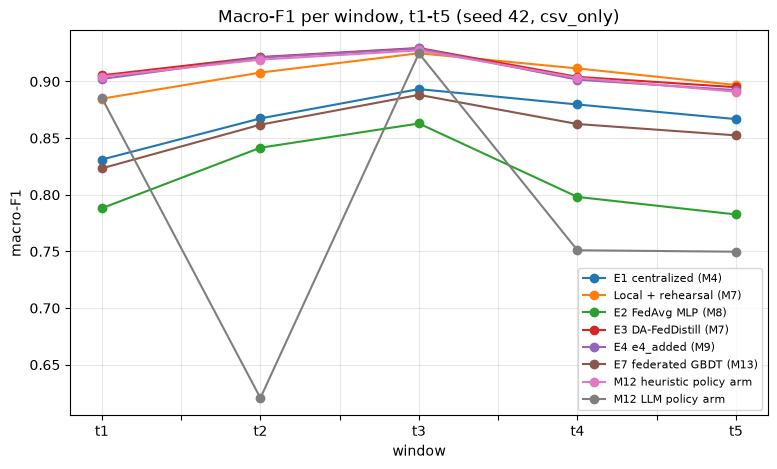

In [18]:
rows = {
    "E1 centralized (M4)": summary("m4", "E1"),
    "Local + rehearsal (M7)": summary("m7", "local_rehearsal"),
    "E2 FedAvg MLP (M8)": summary("m8", "fedavg"),
    "E3 DA-FedDistill (M7)": summary("m7", "e3"),
    "E4 e4_added (M9)": summary("m9", "e4_added"),
    "E7 federated GBDT (M13)": summary("m13", "e7"),
}
m12 = json.loads((R / "m12/full/summary.json").read_text())["arms"]
rows["M12 heuristic policy arm"] = m12["heuristic"]
rows["M12 LLM policy arm"] = m12["llm"]

by_window = pd.DataFrame({k: v["macro_f1_by_window"] for k, v in rows.items()}).T
by_window.columns = [f"t{c}" for c in by_window.columns]
by_window["window avg"] = [v["window_avg_macro_f1"] for v in rows.values()]
by_window["avg excl. t0"] = [v["window_avg_macro_f1_excl_t0"] for v in rows.values()]
display(by_window.sort_values("window avg", ascending=False))

ax = by_window.filter(regex=r"^t\d$").drop(columns="t0").T.plot(marker="o", figsize=(9, 5))
ax.set(xlabel="window", ylabel="macro-F1", title="Macro-F1 per window, t1-t5 (seed 42, csv_only)")
ax.legend(fontsize=8); ax.grid(alpha=.3); plt.show()